# Лабораторная работа 2 - Метод наискорейшего градиентного спуска

Целью работы является нахождение численного решения уравнения методом наискорейшего градиентного спуска.

Реализовать метод наискорейшего градиентного спуска для нахождения точки глобального минимума функции, заданной вашим вариантом.

Вариант 2, функция Била:

$$f(x, y) = (1.5 - x + xy)^2 + (2.25 - x + xy^2)^2 + (2.625 - x + xy^3)^2, \qquad x, y \in [-4.5, 4.5]$$

Глобальный минимум: $f(3, 0.5) = 0$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def f(x, y):
    a = 1.5 - x + x * y
    b = 2.25 - x + x * y ** 2
    c = 2.625 - x + x * y ** 3
    return a ** 2 + b ** 2 + c ** 2

f(3, 0.5), f(-1, -1)

(0.0, 38.703125)

Найти градиент функции, для которой ищется решение

$$\nabla f(X) = [f'_x, f'_y]$$

Обозначим скобки: $a = 1.5 - x + xy$, $b = 2.25 - x + xy^2$, $c = 2.625 - x + xy^3$

$$f'_x = 2a(y - 1) + 2b(y^2 - 1) + 2c(y^3 - 1)$$

$$f'_y = 2a \cdot x + 2b \cdot 2xy + 2c \cdot 3xy^2$$

In [2]:
def grad(x, y):
    a = 1.5 - x + x * y
    b = 2.25 - x + x * y ** 2
    c = 2.625 - x + x * y ** 3

    dx = 2 * a * (y - 1) + 2 * b * (y ** 2 - 1) + 2 * c * (y ** 3 - 1)
    dy = 2 * a * x + 2 * b * 2 * x * y + 2 * c * 3 * x * y ** 2

    return np.array([dx, dy])

grad(3, 0.5), grad(-1, -1)

(array([-0.,  0.]), array([-32.5 , -25.75]))

Находим оптимальный размер шага $\alpha$, такой чтобы шаг уменьшения значения функции был максимальным

$$\alpha_t = \arg\min_{\alpha \geq 0} \varphi(\alpha), \qquad \varphi(\alpha) = f(x_t - \alpha \nabla f(x_t))$$

Это задача одномерной оптимизации, решаем её методом дихотомии на отрезке $[a, b]$:

$$c = \frac{a + b}{2} - \delta, \qquad d = \frac{a + b}{2} + \delta$$

Если $\varphi(c) < \varphi(d)$, то $b = d$, иначе $a = c$. Повторяем, пока $b - a > \varepsilon$

In [3]:
def dichotomy(phi, a, b, eps=1e-8):
    delta = eps / 3

    while b - a > eps:
        m = (a + b) / 2
        if phi(m - delta) < phi(m + delta):
            b = m + delta
        else:
            a = m - delta

    return (a + b) / 2

dichotomy(lambda alpha: (alpha - 0.3) ** 2, 0, 1)

0.29999999928442367

Находим следующее значение x

$$x_{t+1} = x_t - \alpha_t \nabla f(x_t)$$

Проверим критерии остановки

1. $||x_{t+1} - x_t|| \leq \varepsilon_1$
2. $|f(x_{t+1}) - f(x_t)| \leq \varepsilon_2$
3. $||\nabla f(x)|| \leq \varepsilon_3$

Если выполняется любой из критериев, работа алгоритма останавливается

In [4]:
def steepest_descent(start, eps1=1e-8, eps2=1e-14, eps3=1e-6, max_iter=10_000):
    x = np.array(start, dtype=float)
    path = [x]
    alphas = [np.nan]
    stop = "max_iter"

    for _ in range(max_iter):
        g = grad(x[0], x[1])

        if np.linalg.norm(g) <= eps3:
            stop = "eps3"
            break

        def phi(alpha):
            p = x - alpha * g
            return f(p[0], p[1])

        alpha = dichotomy(phi, 0, 1)
        x_new = x - alpha * g

        step = np.linalg.norm(x_new - x)
        drop = abs(f(x_new[0], x_new[1]) - f(x[0], x[1]))

        x = x_new
        path.append(x)
        alphas.append(alpha)

        if np.abs(x).max() > 4.5:
            stop = "вышли из области"
            break
        if step <= eps1:
            stop = "eps1"
            break
        if drop <= eps2:
            stop = "eps2"
            break

    return np.array(path), np.array(alphas), stop

path, alphas, stop = steepest_descent([-1, -1])
values = f(path[:, 0], path[:, 1])

print("шагов:", len(path) - 1)
print("остановка:", stop)
print("точка:", path[-1])
print("значение:", values[-1])

df = pd.DataFrame({
    "x": path[:, 0],
    "y": path[:, 1],
    "f": values,
    "alpha": alphas,
})
df

шагов: 510
остановка: eps3
точка: [2.99999716 0.49999928]
значение: 1.2928496654413536e-12


,x,y,f,alpha
0,-1.000000,-1.000000,3.870312e+01,NaN
1,0.934083,0.532389,6.984688e+00,0.059510
2,1.553463,-0.249354,1.920532e+00,0.097226
3,2.317169,0.355736,2.210197e-01,0.303840
4,2.372293,0.286162,1.376437e-01,0.046273
...,...,...,...,...
506,2.999997,0.499999,1.530484e-12,0.024421
507,2.999997,0.499999,1.464392e-12,0.116909
508,2.999997,0.499999,1.403493e-12,0.024742
509,2.999997,0.499999,1.346185e-12,0.109343


Отобразить графики:
изменение ошибки/значение функции по шагам

$$error_t = ||x_t - x^*||, \qquad x^* = (3, 0.5)$$

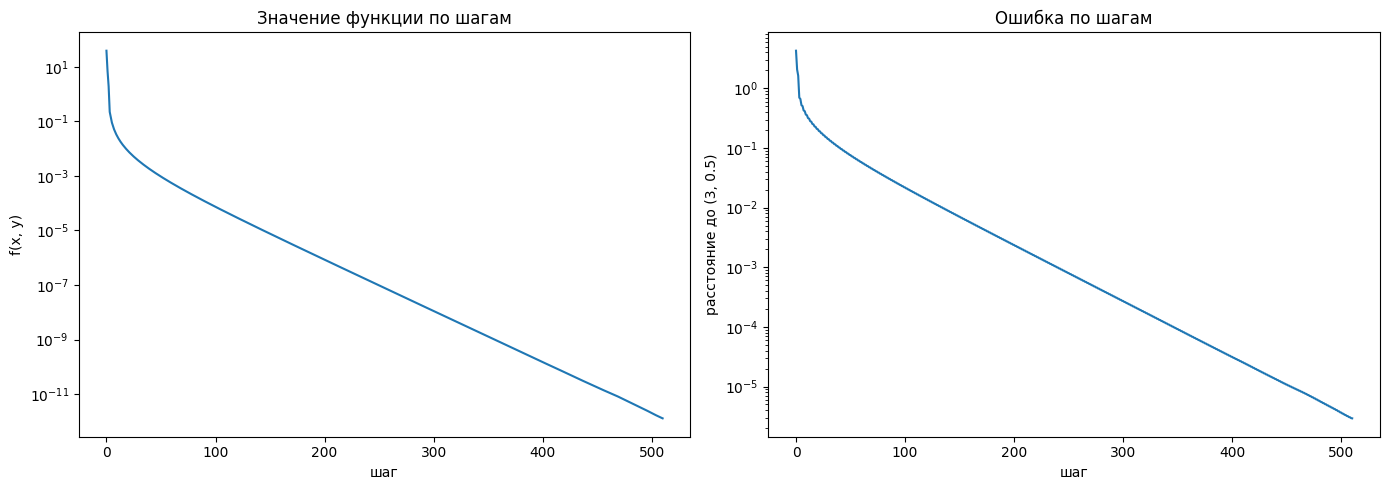

In [5]:
error = np.sqrt((path[:, 0] - 3) ** 2 + (path[:, 1] - 0.5) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(values)
axes[0].set_yscale("log")
axes[0].set_title("Значение функции по шагам")
axes[0].set_xlabel("шаг")
axes[0].set_ylabel("f(x, y)")

axes[1].plot(error)
axes[1].set_yscale("log")
axes[1].set_title("Ошибка по шагам")
axes[1].set_xlabel("шаг")
axes[1].set_ylabel("расстояние до (3, 0.5)")

plt.tight_layout()
plt.show()

график функции от X и Y (это 3-х мерный график)

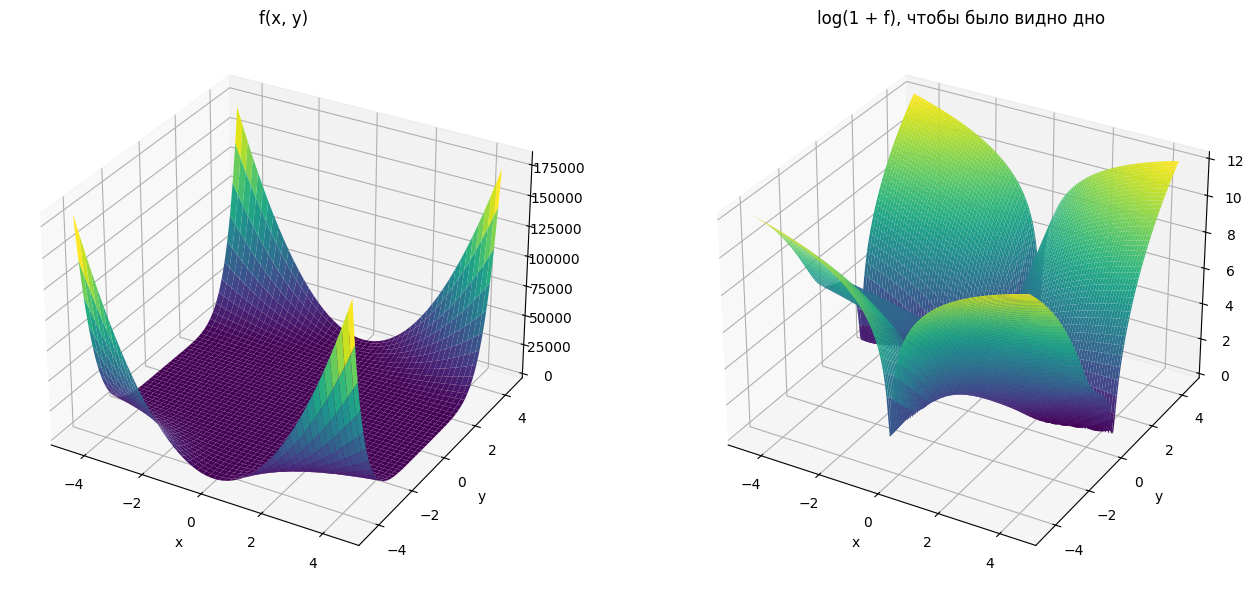

In [6]:
grid = np.linspace(-4.5, 4.5, 200)
X, Y = np.meshgrid(grid, grid)
Z = f(X, Y)

fig = plt.figure(figsize=(14, 6))

ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(X, Y, Z, cmap="viridis")
ax.set_title("f(x, y)")
ax.set_xlabel("x")
ax.set_ylabel("y")

ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.plot_surface(X, Y, np.log1p(Z), cmap="viridis", rcount=100, ccount=100)
ax.set_title("log(1 + f), чтобы было видно дно")
ax.set_xlabel("x")
ax.set_ylabel("y")

plt.tight_layout()
plt.show()

траекторию движения алгоритма на 3-х мерном графике

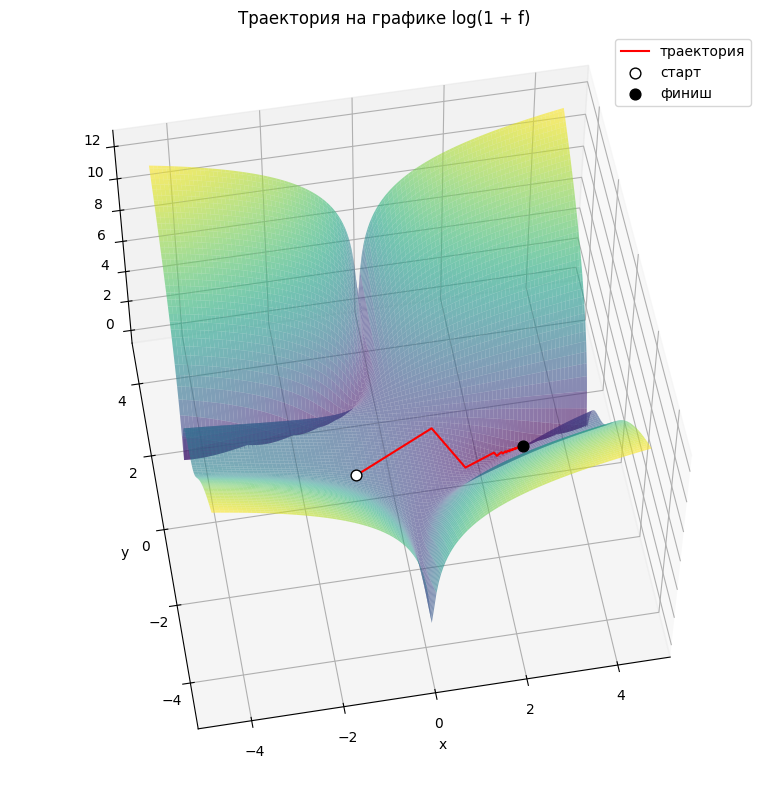

In [7]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d", computed_zorder=False)

ax.plot_surface(X, Y, np.log1p(Z), cmap="viridis", alpha=0.6, rcount=100, ccount=100, zorder=1)
ax.plot(path[:, 0], path[:, 1], np.log1p(values), color="red", zorder=2, label="траектория")
ax.scatter(*path[0], np.log1p(values[0]), color="white", edgecolor="black", s=60, zorder=3, label="старт")
ax.scatter(*path[-1], np.log1p(values[-1]), color="black", s=60, zorder=3, label="финиш")

ax.set_title("Траектория на графике log(1 + f)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.view_init(elev=55, azim=-100)
ax.legend()

plt.tight_layout()
plt.show()

Вид сверху: линии уровня и траектория. Здесь видно, что соседние шаги идут под прямым углом

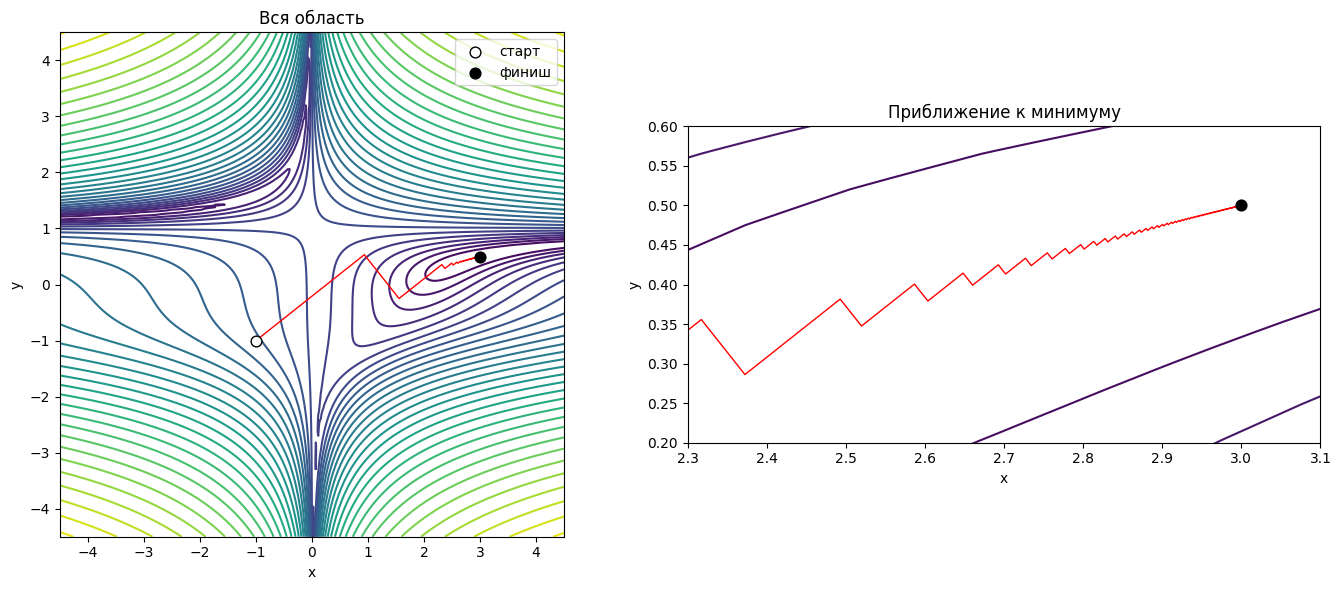

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax in axes:
    ax.contour(X, Y, np.log1p(Z), levels=30, cmap="viridis")
    ax.plot(path[:, 0], path[:, 1], color="red", linewidth=1)
    ax.scatter(path[0, 0], path[0, 1], color="white", edgecolor="black", s=60, zorder=3, label="старт")
    ax.scatter(path[-1, 0], path[-1, 1], color="black", s=60, zorder=3, label="финиш")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

axes[0].set_title("Вся область")
axes[0].legend()

axes[1].set_xlim(2.3, 3.1)
axes[1].set_ylim(0.2, 0.6)
axes[1].set_title("Приближение к минимуму")

plt.tight_layout()
plt.show()

Выбор точки старта: запустим тот же алгоритм из точки $(-2, -2)$

шагов: 5276
остановка: вышли из области
точка: [-4.50019816  1.18656221]
значение: 0.7620671640883286


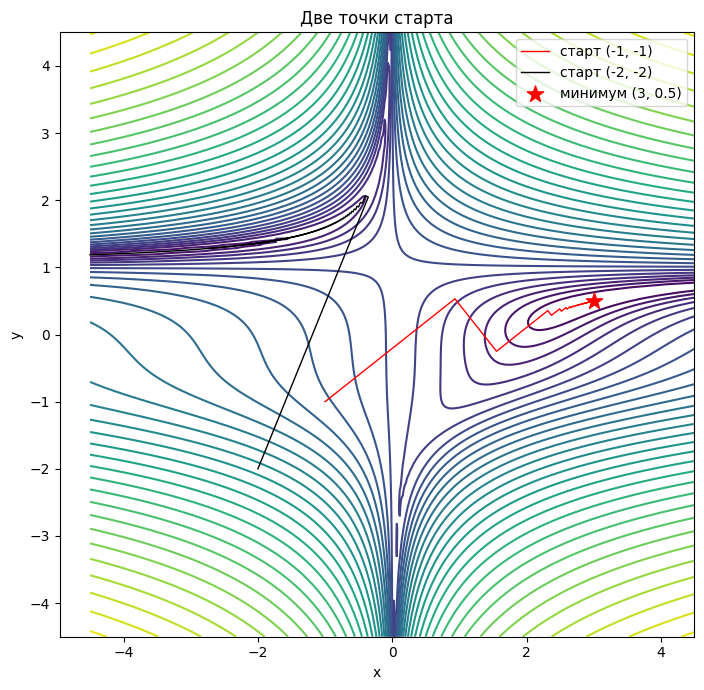

In [9]:
path2, alphas2, stop2 = steepest_descent([-2, -2])
values2 = f(path2[:, 0], path2[:, 1])

print("шагов:", len(path2) - 1)
print("остановка:", stop2)
print("точка:", path2[-1])
print("значение:", values2[-1])

plt.figure(figsize=(8, 7))
plt.contour(X, Y, np.log1p(Z), levels=30, cmap="viridis")
plt.plot(path[:, 0], path[:, 1], color="red", linewidth=1, label="старт (-1, -1)")
plt.plot(path2[:, 0], path2[:, 1], color="black", linewidth=1, label="старт (-2, -2)")
plt.scatter(3, 0.5, marker="*", color="red", s=150, zorder=3, label="минимум (3, 0.5)")
plt.title("Две точки старта")
plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect("equal")
plt.legend()
plt.tight_layout()
plt.show()